Device: cpu
Models loaded

Class: 0
 Model: baseline
  DLG
  iDLG
  GradInv
 Model: fpman0
  DLG
  iDLG
  GradInv
 Model: fpman1
  DLG
  iDLG
  GradInv
 Model: fpman2
  DLG
  iDLG
  GradInv

Class: 1
 Model: baseline
  DLG
  iDLG
  GradInv
 Model: fpman0
  DLG
  iDLG
  GradInv
 Model: fpman1
  DLG
  iDLG
  GradInv
 Model: fpman2
  DLG
  iDLG
  GradInv

Class: 2
 Model: baseline
  DLG
  iDLG
  GradInv
 Model: fpman0
  DLG
  iDLG
  GradInv
 Model: fpman1
  DLG
  iDLG
  GradInv
 Model: fpman2
  DLG
  iDLG
  GradInv

Class: 3
 Model: baseline
  DLG
  iDLG
  GradInv
 Model: fpman0
  DLG
  iDLG
  GradInv
 Model: fpman1
  DLG
  iDLG
  GradInv
 Model: fpman2
  DLG
  iDLG
  GradInv

Class: 4
 Model: baseline
  DLG
  iDLG
  GradInv
 Model: fpman0
  DLG
  iDLG
  GradInv
 Model: fpman1
  DLG
  iDLG
  GradInv
 Model: fpman2
  DLG
  iDLG
  GradInv

Class: 5
 Model: baseline
  DLG
  iDLG
  GradInv
 Model: fpman0
  DLG
  iDLG
  GradInv
 Model: fpman1
  DLG
  iDLG
  GradInv
 Model: fpman2
  DLG
  iDLG


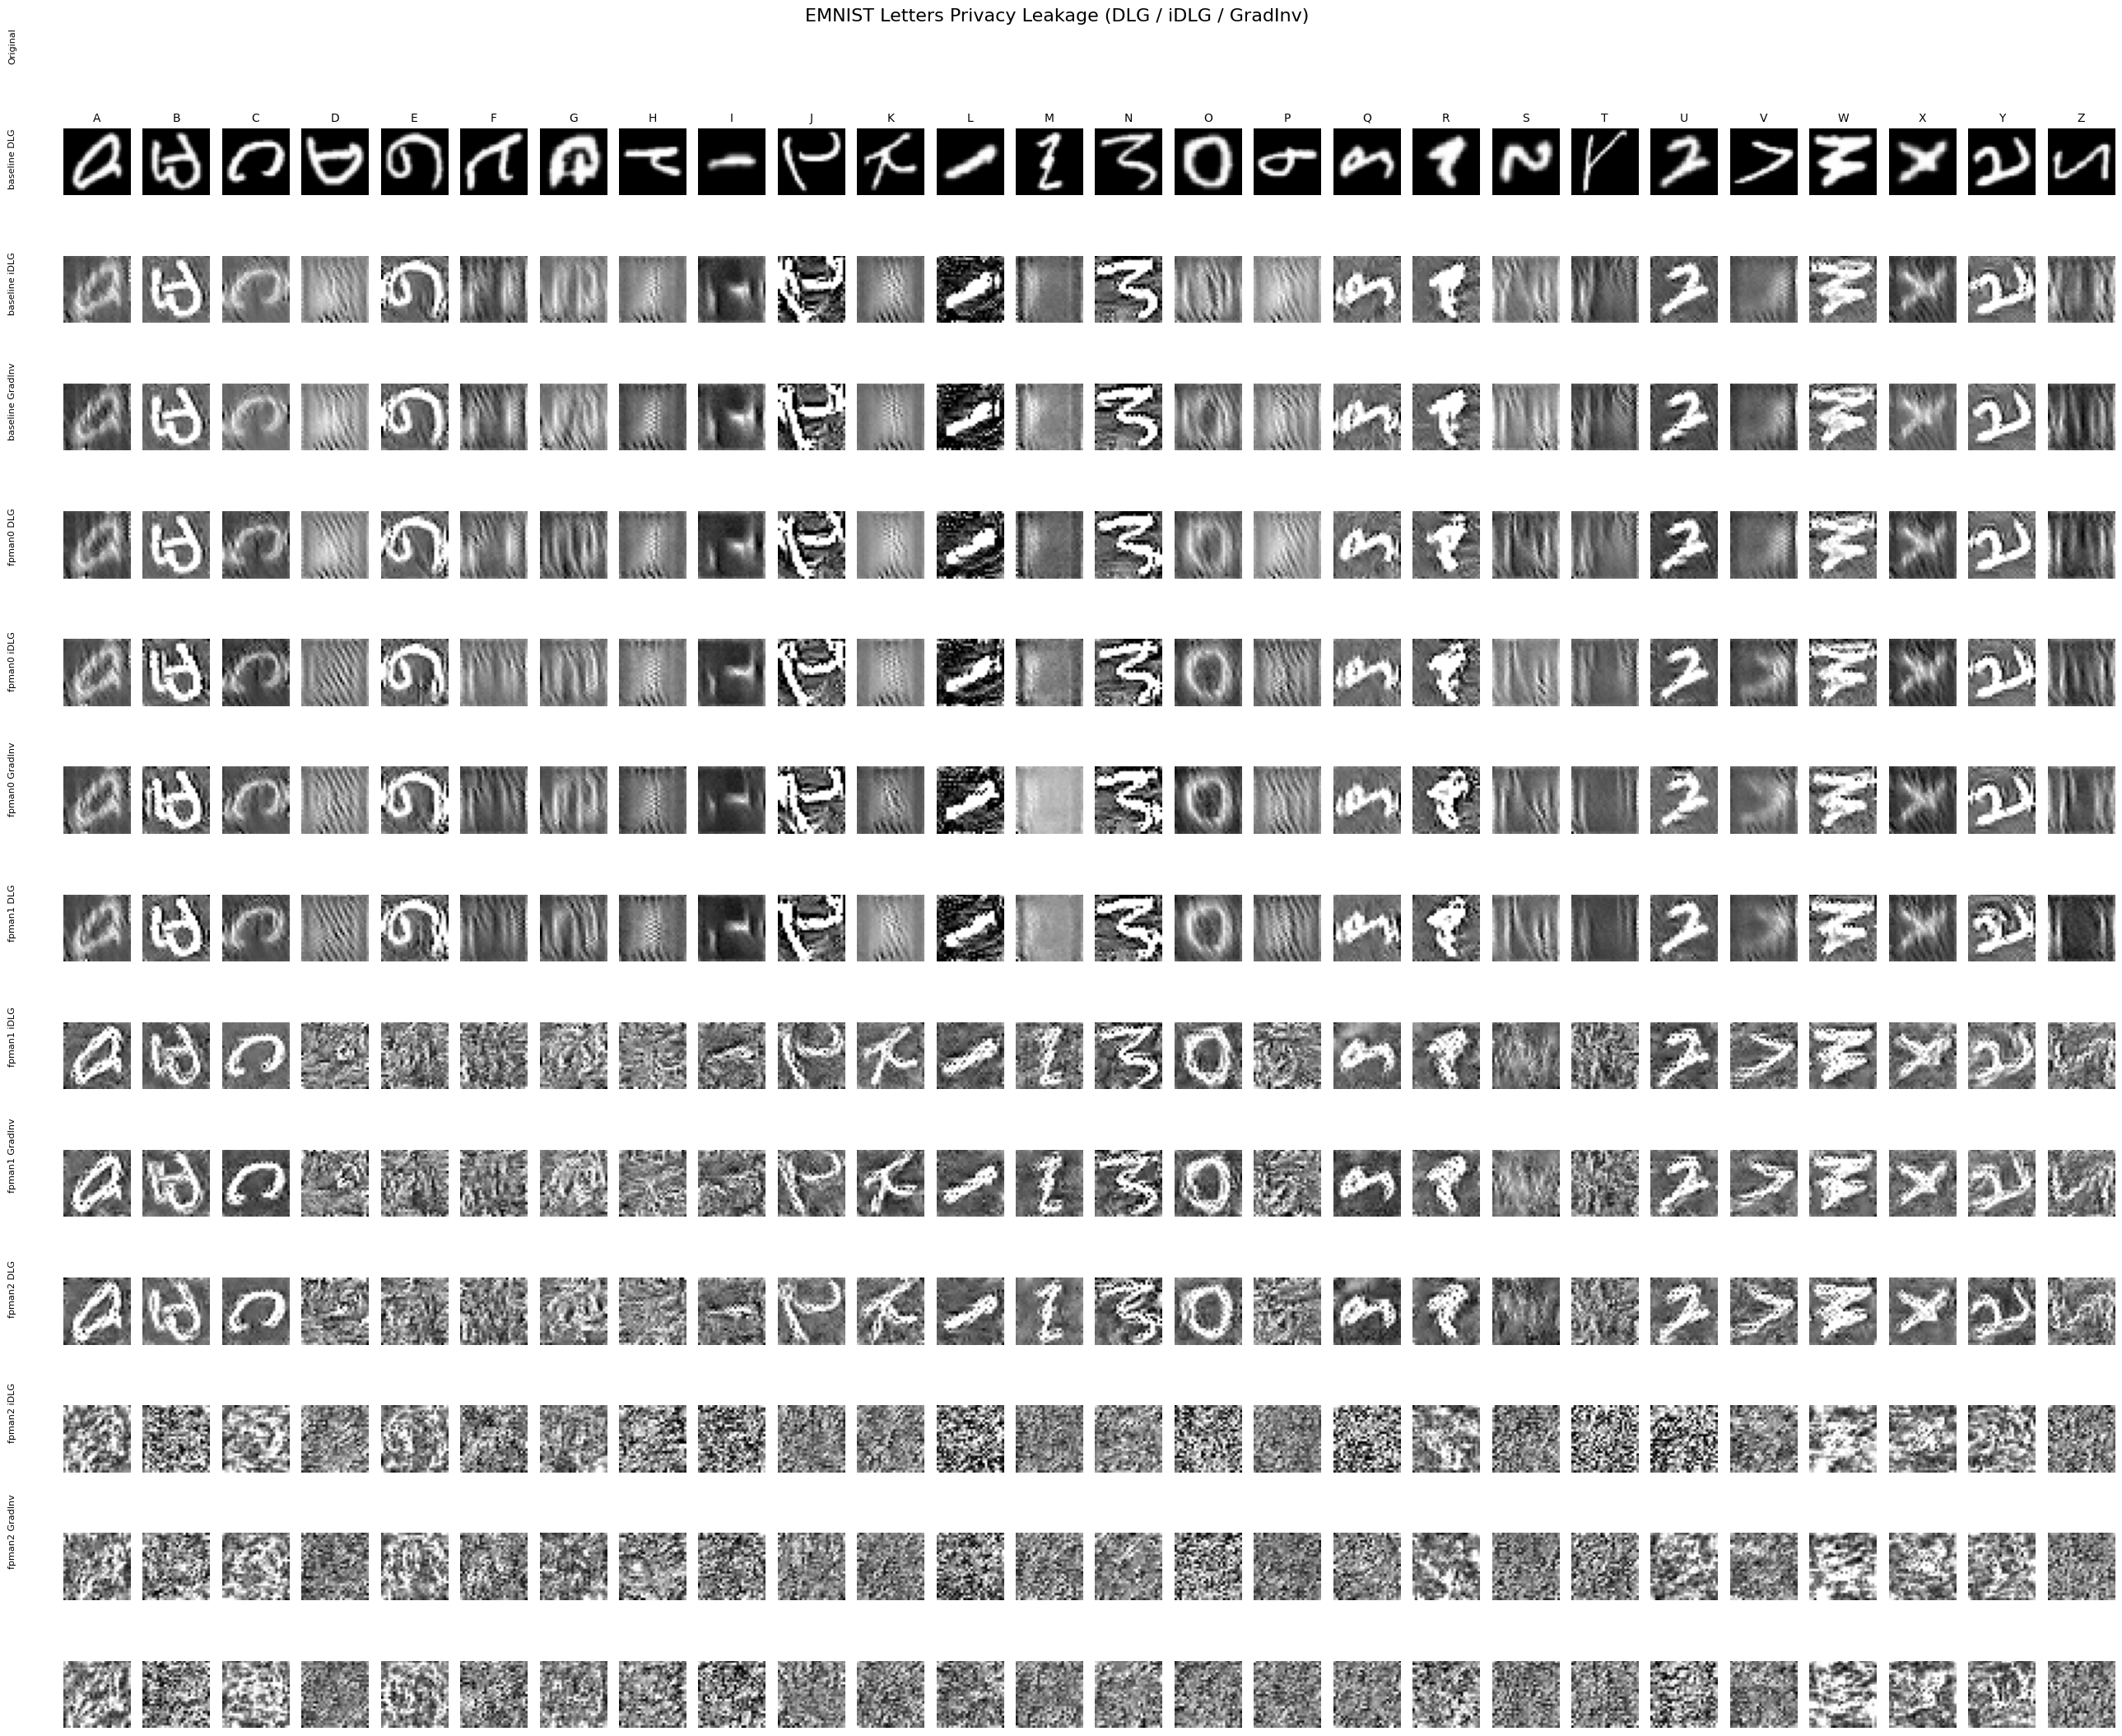

Saved: ./dlg_emnist_letters_4models/letters_attack_results.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ==============================
# DLG + iDLG + GradInversion
# EMNIST Letters (26 classes)
# 4 Models:
# Baseline
# Masking Only
# Masking + ANF=0.1
# Masking + ANF=0.2
# ==============================

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np
import random
import os
from google.colab import files

# -------------------------
# Seed
# -------------------------
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# -------------------------
# Device
# -------------------------
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

# -------------------------
# Save Directory
# -------------------------
SAVE_DIR = "./dlg_emnist_letters_4models"
os.makedirs(SAVE_DIR, exist_ok=True)

# -------------------------
# Dataset (EMNIST Letters)
# -------------------------
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

dataset = torchvision.datasets.EMNIST(
    root="./data",
    split="letters",
    train=True,
    download=True,
    transform=transform
)

# -------------------------
# Model (26 classes)
# -------------------------
NUM_CLASSES = 26

class EMNIST_CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 32, 3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)
        self.pool = nn.MaxPool2d(2)
        self.fc1 = nn.Linear(64 * 7 * 7, 256)
        self.fc2 = nn.Linear(256, NUM_CLASSES)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = x.view(x.size(0), -1)
        x = F.relu(self.fc1(x))
        return self.fc2(x)

# -------------------------
# Load Models
# -------------------------
baseline_model = EMNIST_CNN().to(DEVICE)
fpman_model_0 = EMNIST_CNN().to(DEVICE)
fpman_model_1 = EMNIST_CNN().to(DEVICE)
fpman_model_2 = EMNIST_CNN().to(DEVICE)

baseline_model.load_state_dict(torch.load("Baseline_emnist_letters.pth", map_location=DEVICE))
fpman_model_0.load_state_dict(torch.load("FPMAN_emnist_letters_0.pth", map_location=DEVICE))
fpman_model_1.load_state_dict(torch.load("FPMAN_emnist_letters_1.pth", map_location=DEVICE))
fpman_model_2.load_state_dict(torch.load("FPMAN_emnist_letters_2.pth", map_location=DEVICE))

baseline_model.eval()
fpman_model_0.eval()
fpman_model_1.eval()
fpman_model_2.eval()

print("Models loaded")

# -------------------------
# One sample per class
# -------------------------
letter_samples = {}

for img, label in dataset:
    label = label - 1  # EMNIST letters are 1–26 → convert to 0–25
    if label not in letter_samples:
        letter_samples[label] = img
    if len(letter_samples) == 26:
        break

# -------------------------
# Gradients
# -------------------------
def get_gradients(model, image, label):
    model.zero_grad()
    pred = model(image)
    loss = F.cross_entropy(pred, label)
    grads = torch.autograd.grad(loss, model.parameters())
    return grads

# -------------------------
# TV loss
# -------------------------
def total_variation(x):
    tv_h = (x[:, :, 1:, :] - x[:, :, :-1, :]).pow(2).mean()
    tv_w = (x[:, :, :, 1:] - x[:, :, :, :-1]).pow(2).mean()
    return tv_h + tv_w

# -------------------------
# DLG
# -------------------------
def dlg_attack(model, original_grads, image_shape, label, steps=400, lr=0.05):

    dummy = (torch.randn(image_shape, device=DEVICE) * 0.1).detach()
    dummy.requires_grad = True
    opt = torch.optim.Adam([dummy], lr=lr)

    for _ in range(steps):
        opt.zero_grad()
        pred = model(dummy)
        loss = F.cross_entropy(pred, label)

        grads = torch.autograd.grad(loss, model.parameters(), create_graph=True)

        grad_diff = 0
        for g1, g2 in zip(grads, original_grads):
            grad_diff += ((g1 - g2) ** 2).sum()

        grad_diff.backward()
        opt.step()

        with torch.no_grad():
            dummy.clamp_(-1, 1)

    return dummy.detach()

# -------------------------
# iDLG
# -------------------------
def idlg_attack(model, original_grads, image_shape, steps=400, lr=0.05):

    last_grad = original_grads[-1]
    recovered_label = torch.argmin(last_grad).unsqueeze(0).to(DEVICE)

    dummy = (torch.randn(image_shape, device=DEVICE) * 0.1).detach()
    dummy.requires_grad = True
    opt = torch.optim.Adam([dummy], lr=lr)

    for _ in range(steps):
        opt.zero_grad()
        pred = model(dummy)
        loss = F.cross_entropy(pred, recovered_label)

        grads = torch.autograd.grad(loss, model.parameters(), create_graph=True)

        grad_diff = 0
        for g1, g2 in zip(grads, original_grads):
            grad_diff += ((g1 - g2) ** 2).sum()

        grad_diff.backward()
        opt.step()

        with torch.no_grad():
            dummy.clamp_(-1, 1)

    return dummy.detach()

# -------------------------
# GradInversion
# -------------------------
def gradinv_attack(model, original_grads, image_shape, label, steps=400, lr=0.05, tv=1e-4):

    dummy = (torch.randn(image_shape, device=DEVICE) * 0.1).detach()
    dummy.requires_grad = True
    opt = torch.optim.Adam([dummy], lr=lr)

    for _ in range(steps):
        opt.zero_grad()

        pred = model(dummy)
        loss = F.cross_entropy(pred, label)

        grads = torch.autograd.grad(loss, model.parameters(), create_graph=True)

        grad_diff = 0
        for g1, g2 in zip(grads, original_grads):
            grad_diff += ((g1 - g2) ** 2).sum()

        grad_diff += tv * total_variation(dummy)

        grad_diff.backward()
        opt.step()

        with torch.no_grad():
            dummy.clamp_(-1, 1)

    return dummy.detach()

# -------------------------
# Models
# -------------------------
models = {
    "baseline": baseline_model,
    "fpman0": fpman_model_0,
    "fpman1": fpman_model_1,
    "fpman2": fpman_model_2
}

# -------------------------
# Storage
# -------------------------
results = {k: {"dlg": [], "idlg": [], "gi": []} for k in models}
original_imgs = []

# -------------------------
# Run attacks
# -------------------------
for c in range(26):

    print(f"\nClass: {c}")

    img = letter_samples[c].unsqueeze(0).to(DEVICE)
    label = torch.tensor([c]).to(DEVICE)

    original_imgs.append(img.cpu().numpy()[0][0])

    for name, model in models.items():

        print(" Model:", name)

        grads = get_gradients(model, img, label)

        print("  DLG")
        r1 = dlg_attack(model, grads, img.shape, label)
        results[name]["dlg"].append(r1.cpu().numpy()[0][0])

        print("  iDLG")
        r2 = idlg_attack(model, grads, img.shape)
        results[name]["idlg"].append(r2.cpu().numpy()[0][0])

        print("  GradInv")
        r3 = gradinv_attack(model, grads, img.shape, label)
        results[name]["gi"].append(r3.cpu().numpy()[0][0])

# -------------------------
# Visualization (26 rows)
# -------------------------
row_names = ["Original"]

for m in models:
    row_names += [
        f"{m} DLG",
        f"{m} iDLG",
        f"{m} GradInv"
    ]

all_rows = [
    original_imgs,

    results["baseline"]["dlg"],
    results["baseline"]["idlg"],
    results["baseline"]["gi"],

    results["fpman0"]["dlg"],
    results["fpman0"]["idlg"],
    results["fpman0"]["gi"],

    results["fpman1"]["dlg"],
    results["fpman1"]["idlg"],
    results["fpman1"]["gi"],

    results["fpman2"]["dlg"],
    results["fpman2"]["idlg"],
    results["fpman2"]["gi"]
]

fig, axes = plt.subplots(len(all_rows), 26, figsize=(26, 22))

for r in range(len(all_rows)):
    for c in range(26):
        axes[r, c].imshow(all_rows[r][c], cmap="gray")
        axes[r, c].axis("off")

for c in range(26):
    axes[0, c].set_title(chr(ord('A') + c), fontsize=10)

for i, name in enumerate(row_names):
    fig.text(0.01, 0.95 - i * (0.9 / len(row_names)), name, rotation=90, fontsize=8)

plt.suptitle("EMNIST Letters Privacy Leakage (DLG / iDLG / GradInv)", fontsize=16)

plt.tight_layout(rect=[0.03, 0, 1, 0.96])

save_path = os.path.join(SAVE_DIR, "letters_attack_results.png")
plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", save_path)

files.download(save_path)

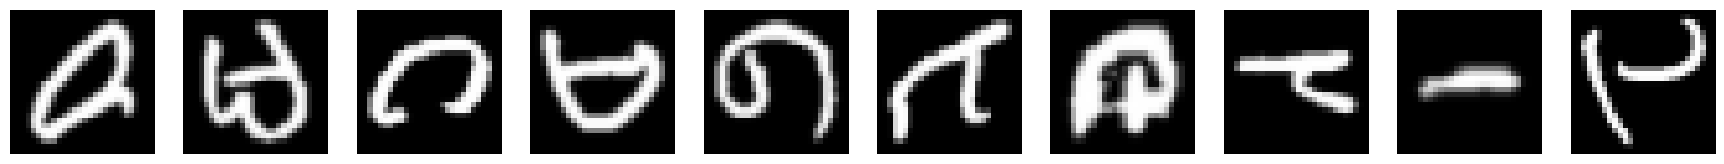

Figure saved: ./dlg_emnist_letters_4models/original.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

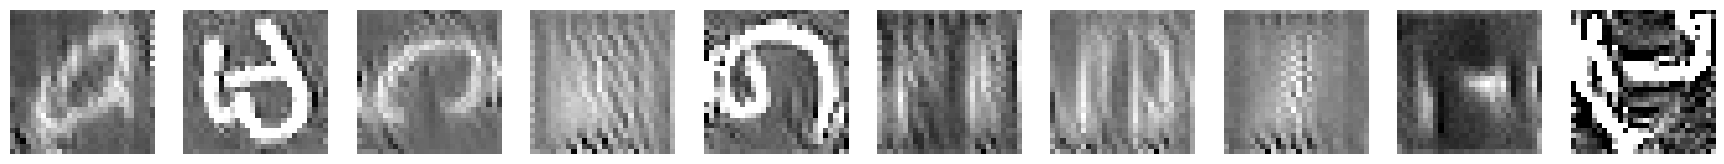

Figure saved: ./dlg_emnist_letters_4models/baseline_dlg.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

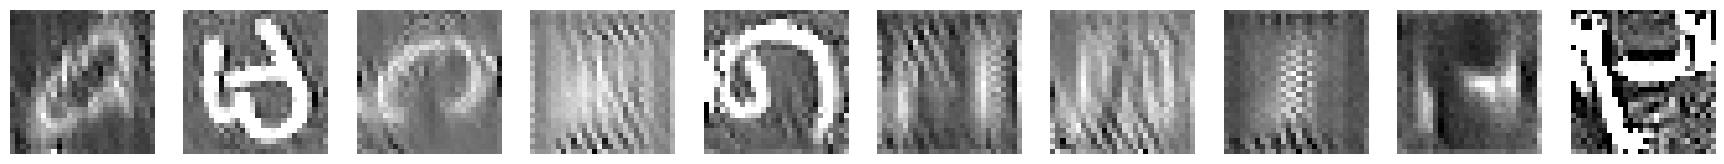

Figure saved: ./dlg_emnist_letters_4models/baseline_idlg.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

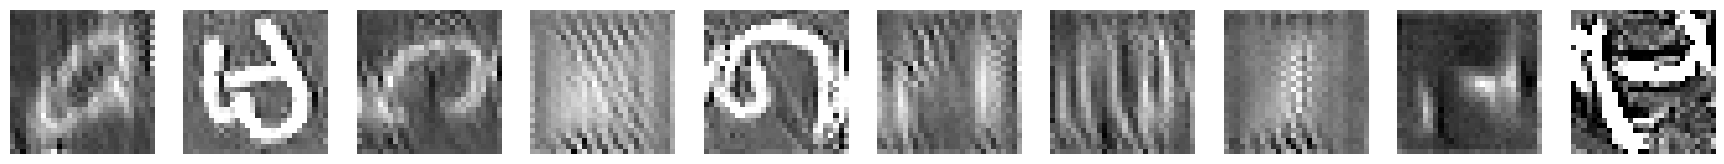

Figure saved: ./dlg_emnist_letters_4models/baseline_gradinv.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

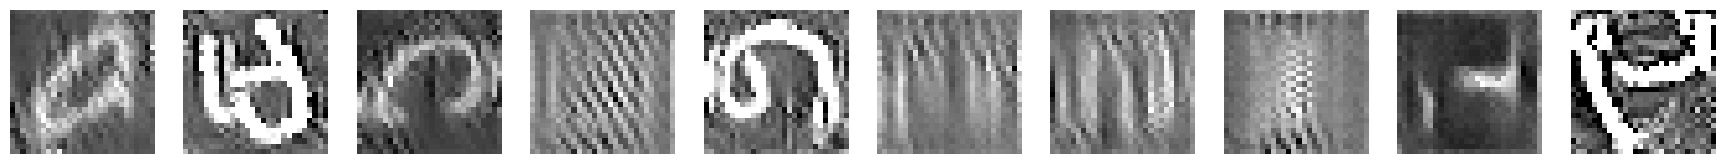

Figure saved: ./dlg_emnist_letters_4models/fpman0_dlg.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

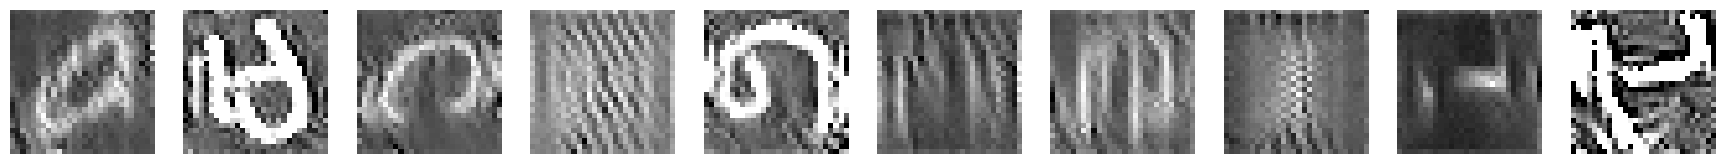

Figure saved: ./dlg_emnist_letters_4models/fpman0_idlg.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

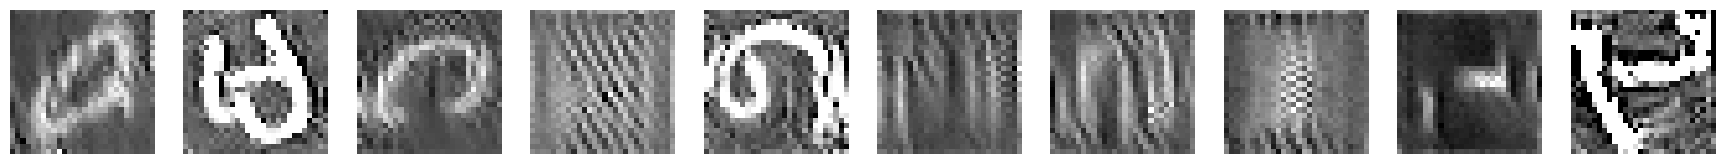

Figure saved: ./dlg_emnist_letters_4models/fpman0_gradinv.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

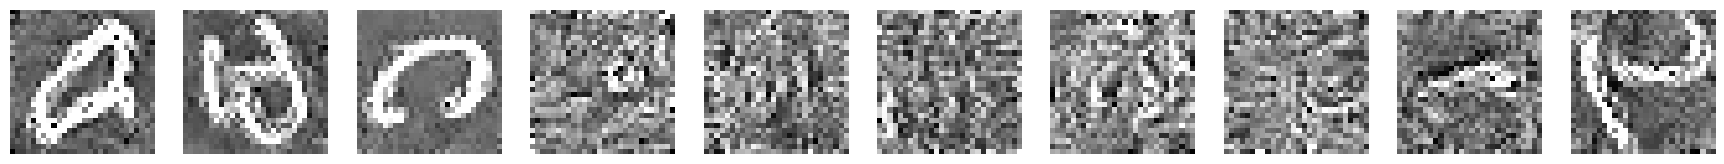

Figure saved: ./dlg_emnist_letters_4models/fpman1_dlg.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

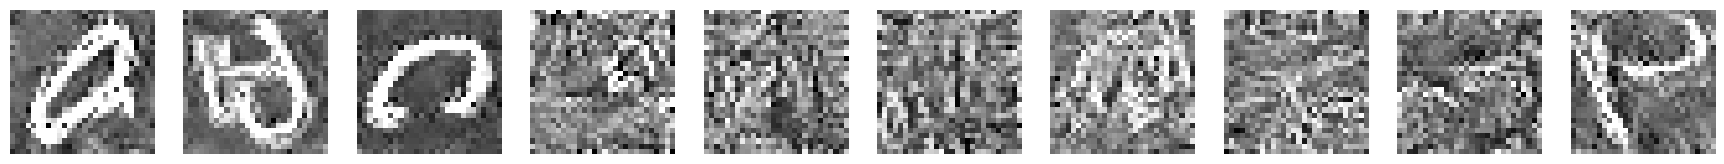

Figure saved: ./dlg_emnist_letters_4models/fpman1_idlg.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

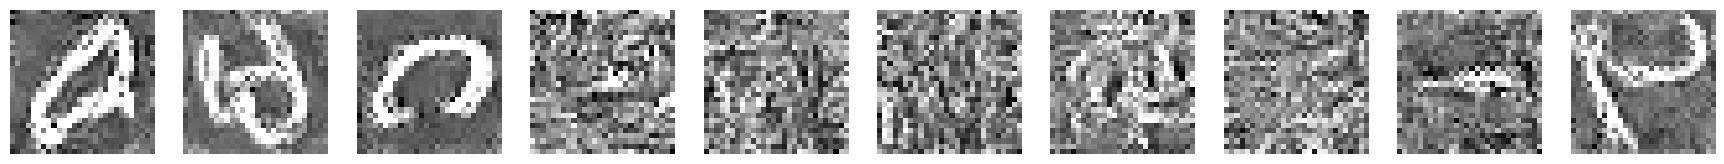

Figure saved: ./dlg_emnist_letters_4models/fpman1_gradinv.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

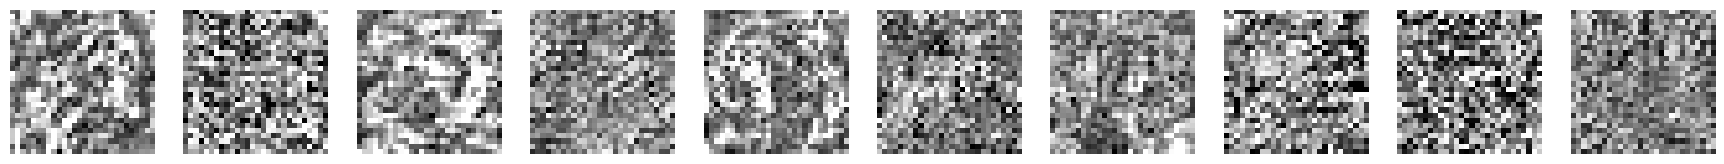

Figure saved: ./dlg_emnist_letters_4models/fpman2_dlg.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

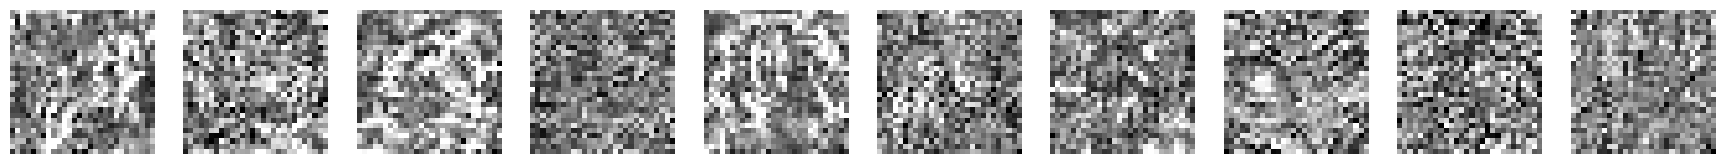

Figure saved: ./dlg_emnist_letters_4models/fpman2_idlg.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

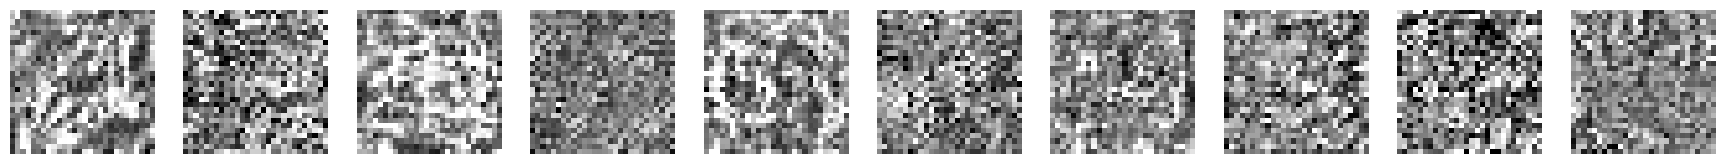

Figure saved: ./dlg_emnist_letters_4models/fpman2_gradinv.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# -------------------------
# Visualization: 13 Separate Images with Thicker Margin (EMNIST Letters / 4 Models)
# -------------------------

row_names = [
    "original",

    "baseline_dlg",
    "baseline_idlg",
    "baseline_gradinv",

    "fpman0_dlg",
    "fpman0_idlg",
    "fpman0_gradinv",

    "fpman1_dlg",
    "fpman1_idlg",
    "fpman1_gradinv",

    "fpman2_dlg",
    "fpman2_idlg",
    "fpman2_gradinv"
]

all_rows = [
    original_imgs,

    results["baseline"]["dlg"],
    results["baseline"]["idlg"],
    results["baseline"]["gi"],

    results["fpman0"]["dlg"],
    results["fpman0"]["idlg"],
    results["fpman0"]["gi"],

    results["fpman1"]["dlg"],
    results["fpman1"]["idlg"],
    results["fpman1"]["gi"],

    results["fpman2"]["dlg"],
    results["fpman2"]["idlg"],
    results["fpman2"]["gi"],
]

for idx, row in enumerate(all_rows):

    fig, axes = plt.subplots(1, 10, figsize=(22, 3))

    for c in range(10):
        axes[c].imshow(row[c], cmap="gray")
        axes[c].axis("off")

    save_path = os.path.join(SAVE_DIR, f"{row_names[idx]}.png")

    plt.savefig(save_path, dpi=300, bbox_inches='tight', pad_inches=0.2)
    plt.show()

    print("Figure saved:", save_path)

    files.download(save_path)